# 04· When do people ride?

**Who Gets a Bluebike?** · CP 101 final project

A histogram of trips by the hour they started, for trips that began at a station inside Boston in 2024. The data has no rider IDs, so each trip counts as one rider.

Run `01_clean_data.ipynb` first. It saves every clean trip, with an `hour` column, to `data/interim/trips/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

INTERIM_TRIPS = Path("../data/interim/trips")
CLEAN = Path("../data/clean")

trip_files = sorted(INTERIM_TRIPS.glob("*.parquet"))

# read only the columns we need, so the many trips fit easily in memory
trips = pd.concat(
    [pd.read_parquet(p, columns=["start_station_id", "hour", "is_weekend"]) for p in trip_files],
    ignore_index=True,
)

# keep trips that started at a station inside Boston, to match the rest of the project
stations = pd.read_csv(CLEAN / "stations.csv", dtype={"station_id": str})
boston_ids = stations.loc[stations["in_boston"], "station_id"]
trips = trips[trips["start_station_id"].isin(boston_ids)]

print(len(trips), "trips started in Boston")

2599793 trips started in Boston


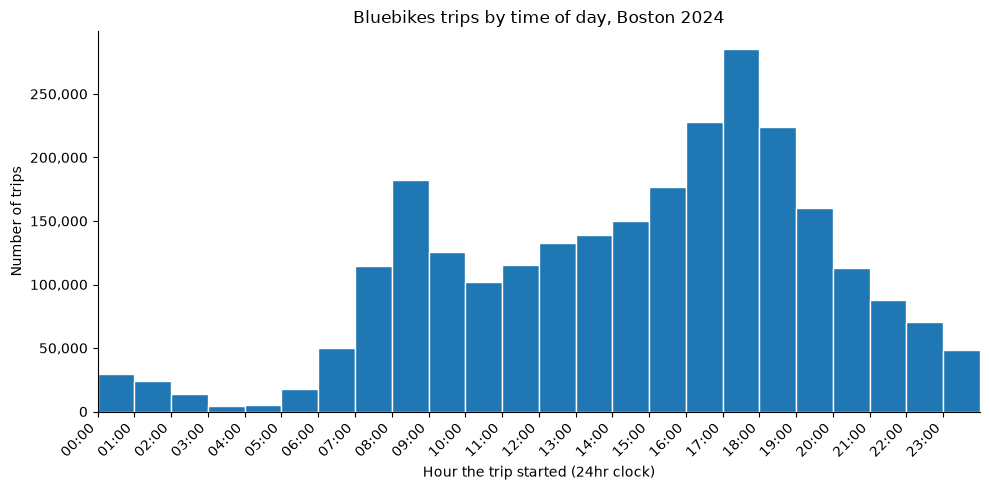

busiest hour starts at 17:00 with 285,007 trips


In [74]:
# a histogram of start hours: 24 bins, one per hour, from 00:00 to 24:00
hour_labels = [str(h).zfill(2) + ":00" for h in range(24)]   # 24-hour clock: "00:00" through "23:00"

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(trips["hour"], bins=range(25), edgecolor="white")
ax.set_xticks(range(24))
ax.set_xticklabels(hour_labels, rotation=45, ha="right")
ax.set_xlim(0, 24)
ax.set_xlabel("Hour the trip started (24hr clock)")
ax.set_ylabel("Number of trips")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
ax.set_title("Bluebikes trips by time of day, Boston 2024")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("busiest hour starts at", hour_labels[by_hour.idxmax()], "with", f"{by_hour.max():,}", "trips")

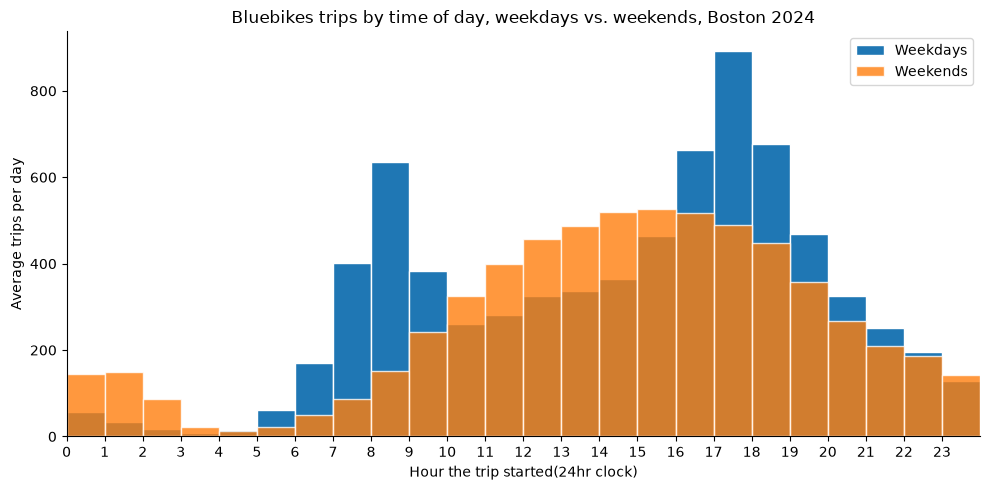

In [73]:
# weekdays and weekends follow different patterns, so plot them side by side.
# divide by the number of days of each kind so the two bars are comparable
WEEKDAYS_2024 = 262
WEEKEND_DAYS_2024 = 104

weekday = trips.loc[~trips["is_weekend"], "hour"].value_counts().reindex(range(24), fill_value=0) / WEEKDAYS_2024
weekend = trips.loc[trips["is_weekend"], "hour"].value_counts().reindex(range(24), fill_value=0) / WEEKEND_DAYS_2024

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(weekday.index, weights=weekday.values, bins=range(25), alpha=1, label="Weekdays", edgecolor="white")
ax.hist(weekend.index, weights=weekend.values, bins=range(25),  alpha=0.8, label="Weekends", edgecolor="white")
#ax.hist(trips["hour"], bins=range(25), edgecolor="white")
#ax.bar([h + 0.05 for h in range(24)], weekday.values, width=0.45, align="edge", label="Weekday")
#ax.bar([h + 0.5 for h in range(24)], weekend.values, width=0.45, align="edge", label="Weekend")
ax.set_xticks(range(24))
ax.set_xticklabels(hour_labels)
ax.set_xlim(0, 24)
ax.set_xlabel("Hour the trip started(24hr clock)")
ax.set_ylabel("Average trips per day")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
ax.set_title("Bluebikes trips by time of day, weekdays vs. weekends, Boston 2024")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()